# 01 — Sources de données et test de faisabilité (GO / NO-GO)

**Question business.** Peut-on corriger un capteur de particules fines à ≈ 30 € pour qu'il approche une
station officielle, et jusqu'à quelle distance d'une station la correction reste-t-elle fiable ?

**But de ce notebook.** Avant d'écrire un pipeline lourd, on vérifie *sur de vraies données* que le projet tient :

1. à quoi ressemblent vraiment les fichiers des capteurs citoyens (Sensor.Community) ;
2. à quoi ressemblent les mesures des stations officielles (Agence européenne de l'environnement, EEA) ;
3. quels capteurs étaient actifs en 2024–2025, et où ;
4. combien de couples *capteur citoyen ↔ station officielle* on peut former selon la distance ;
5. combien de place cela prendra sur le disque.

On conclut par une recommandation chiffrée **GO / NO-GO**.

Vocabulaire utilisé dans tout le projet :

- **PM2.5 / PM10** : masse de particules de diamètre inférieur à 2,5 / 10 micromètres par mètre cube d'air (µg/m³).
- **Capteur citoyen** : boîtier à bas coût (le plus courant est le **SDS011**, un compteur optique à ≈ 30 €) installé par un particulier.
- **Sonde météo** : petit capteur d'humidité et de température (BME280, DHT22…) souvent branché sur le même boîtier.
- **Site** (`location`) : l'emplacement physique d'un boîtier ; la sonde de particules et la sonde météo ont des identifiants différents mais le même site.
- **Station de référence** : station réglementaire dont les mesures sont **vérifiées** par l'organisme national (notre « vérité terrain »).
- **Paire** : un capteur citoyen associé à une station de référence proche.

Toute la logique est dans `src/aircalib/` ; ce notebook l'appelle, montre les résultats et les commente.

## 0. Préparation

**Ce qu'on fait.** On charge la configuration centrale (`configs/default.yaml`) et les modules du projet.

**Pourquoi.** Aucune valeur (dates, rayons, URL) n'est écrite en dur dans le notebook : tout vient de la configuration.
Les résultats réseau sont mis en cache dans `data/meta/`, donc ré-exécuter ce notebook est rapide.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.ingest import discovery, eea
from aircalib.logging import setup_logging

setup_logging("WARNING")
settings = get_settings()
TODAY = date(2026, 10, 13)  # date of the discovery run (cache key of the live snapshot)
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config(tbl_rows=30, tbl_cols=14, fmt_str_lengths=45, tbl_width_chars=160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("période étudiée :", settings.period.start, "→", settings.period.end)

période étudiée : 2024-01-01 → 2025-12-31


## 1. Un fichier brut de capteur citoyen

**Ce qu'on fait.** On télécharge trois jours de données réelles (15–17 mars 2024) pour trois capteurs pris au hasard :
un capteur de particules SDS011 et deux sondes météo (BME280 et DHT22).

**Pourquoi.** Règle d'or du projet : *ne jamais supposer un format*. On regarde les colonnes, les types et les valeurs
avant d'écrire le moindre parseur.

In [2]:
examples = [
    {"sensor_type": "sds011", "sensor_id": 7334},
    {"sensor_type": "bme280", "sensor_id": 18678},
    {"sensor_type": "dht22", "sensor_id": 7530},
]
raw = {}
for e in examples:
    raw[e["sensor_type"]] = await discovery.sensor_days(settings, e, date(2024, 3, 15), 3, TODAY)
for sensor_type, frame in raw.items():
    print(f"{sensor_type}: {frame.height} lignes, colonnes = {frame.columns}")
raw["sds011"].head(4)

sds011: 1684 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'P1', 'durP1', 'ratioP1', 'P2', 'durP2', 'ratioP2']
bme280: 843 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'pressure', 'altitude', 'pressure_sealevel', 'temperature', 'humidity']
dht22: 1746 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'temperature', 'humidity']


sensor_id,sensor_type,location,lat,lon,timestamp,P1,durP1,ratioP1,P2,durP2,ratioP2
str,str,str,str,str,str,str,str,str,str,str,str
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:02:11""","""12.55""",null,null,"""7.03""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:04:43""","""9.95""",null,null,"""6.50""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:07:09""","""12.30""",null,null,"""7.05""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:09:35""","""11.02""",null,null,"""6.38""",null,null


**Ce qu'on observe.** 
Les trois fichiers ont un en-tête et des colonnes séparées par des points-virgules. Les six premières colonnes
(`sensor_id`, `sensor_type`, `location`, `lat`, `lon`, `timestamp`) sont communes à tous les types ; viennent ensuite
les mesures propres au type : `P1` (PM10) et `P2` (PM2.5) pour le SDS011, `pressure`, `temperature`, `humidity` pour le
BME280, `temperature` et `humidity` pour le DHT22. Tout est lu **en texte** : à l'ingestion on ne transforme rien
(règle de la couche *bronze*), le typage se fera au nettoyage. L'horodatage n'a pas de fuseau (on montre au § 3 que
c'est de l'UTC). Le capteur 7334 est en Bulgarie (42,6° N ; 23,4° E) : l'archive est **mondiale**, il faudra filtrer
par position.

**Ce qu'on fait.** On mesure trois choses sur ces fichiers : la cadence de mesure (écart médian entre deux lignes),
les colonnes toujours vides, et la part de mesures d'humidité « collées » au plafond (≥ 99,9 %).

**Pourquoi.** La cadence fixe le nombre de mesures attendues par heure (utile pour la règle de complétude de l'étape 3) ;
une humidité bloquée à 100 % est un symptôme classique de sonde saturée ou en panne.

In [3]:
def profile(frame: pl.DataFrame) -> dict:
    ts = frame["timestamp"].str.to_datetime("%Y-%m-%dT%H:%M:%S").sort()
    empty = [c for c in frame.columns if frame[c].null_count() == frame.height]
    out = {
        "lignes": frame.height,
        "cadence_médiane_s": ts.diff().dt.total_seconds().median(),
        "colonnes_vides": empty,
    }
    if "humidity" in frame.columns:
        rh = frame["humidity"].cast(pl.Float64)
        out |= {
            "humidité_min": rh.min(),
            "humidité_max": rh.max(),
            "part_humidité_≥99.9": round((rh >= 99.9).mean(), 3),
        }
    if "P2" in frame.columns:
        p2 = frame["P2"].cast(pl.Float64)
        out |= {"PM2.5_min": p2.min(), "PM2.5_médiane": p2.median(), "PM2.5_max": p2.max()}
    return out


pl.DataFrame([{"capteur": k, **{k2: str(v2) for k2, v2 in profile(v).items()}} for k, v in raw.items()])

capteur,lignes,cadence_médiane_s,colonnes_vides,PM2.5_min,PM2.5_médiane,PM2.5_max,humidité_min,humidité_max,part_humidité_≥99.9
str,str,str,str,str,str,str,str,str,str
"""sds011""","""1684""","""146.0""","""['durP1', 'ratioP1', 'durP2', 'ratioP2']""","""1.38""","""6.88""","""15.88""",null,null,null
"""bme280""","""843""","""306.0""","""['altitude', 'pressure_sealevel']""",null,null,null,"""54.23""","""100.0""","""0.553"""
"""dht22""","""1746""","""146.0""","""[]""",null,null,null,"""19.2""","""99.9""","""0.497"""


**Ce qu'on observe.** 
- **Cadence** : ≈ 146 s entre deux mesures pour le SDS011 et le DHT22, ≈ 306 s pour ce BME280. Le nombre de
  mesures attendues par heure dépend donc du capteur (≈ 25 ou ≈ 12) : la règle de complétude horaire de l'étape 3
  utilisera la cadence propre à chaque capteur, pas une valeur fixe.
- **Colonnes toujours vides** : `durP1`, `ratioP1`, `durP2`, `ratioP2` (héritées d'un ancien modèle de capteur, le
  PPD42NS) et, pour le BME280, `altitude` et `pressure_sealevel`. On les ignorera.
- **Humidité** : sur ces trois jours de mars, **55 %** des mesures du BME280 et **50 %** de celles du DHT22 valent
  99,9 % ou plus. Une humidité de 100 % existe (brouillard), mais aussi souvent c'est le symptôme classique d'une sonde
  saturée. La variable la plus importante du modèle est donc aussi la plus sale : elle aura sa règle de qualité dédiée.
- Les PM2.5 de ce SDS011 restent dans une plage plausible (1,4 à 15,9 µg/m³).

## 2. L'archive : quels capteurs étaient actifs en 2024–2025 ?

**Ce qu'on fait.** L'archive publie un dossier par jour contenant un fichier par capteur. On lit la *liste des fichiers*
(pas leur contenu) d'un jour par mois — le 15 — soit 24 listes pour 2024–2025.

**Pourquoi.** L'API « live » ne montre que les capteurs actifs *aujourd'hui* : un capteur tombé en panne en 2025 y est invisible.
Lister les 731 jours prendrait ≈ 13 h (chaque liste fait ≈ 5 Mo et met ≈ 65 s à arriver) ; un jour par mois suffit
pour savoir *quels mois* chaque capteur a fonctionné. La limite (un capteur actif seulement entre deux 15 est manqué)
est notée au journal ; l'activité exacte sera recalculée à l'étape 2.

In [4]:
listings = await discovery.collect_listings(settings, TODAY)
print(f"{listings.height:,} fichiers capteur-jour sur {listings['date'].n_unique()} jours échantillonnés")
by_type = (
    listings.group_by("sensor_type")
    .agg(
        fichiers=pl.len(),
        capteurs=pl.col("sensor_id").n_unique(),
        part_indoor=pl.col("indoor").mean().round(3),
    )
    .sort("capteurs", descending=True)
)
by_type.head(12)

515,616 fichiers capteur-jour sur 24 jours échantillonnés


sensor_type,fichiers,capteurs,part_indoor
str,u32,u32,f64
"""sds011""",256554,16451,0.027
"""bme280""",114482,7817,0.041
"""dht22""",96231,5990,0.031
"""sps30""",8702,686,0.028
"""laerm""",6194,524,0.02
"""bmp280""",5870,473,0.056
"""pms5003""",5263,398,0.113
"""pms7003""",4917,362,0.066
"""sht31""",5823,360,0.022


**Ce qu'on observe.** 
Les 24 listes contiennent **515 616 fichiers** capteur-jour. Le SDS011 domine (16 451 capteurs distincts dans le
monde), devant les sondes d'humidité BME280 (7 817) et DHT22 (5 990). Les capteurs de particules PMS5003, PMS7003 et
SPS30 sont marginaux (moins de 700 chacun). Les capteurs déclarés *indoor* (suffixe `_indoor` dans le nom du fichier)
sont rares (2,7 % des fichiers SDS011) mais existent : un capteur d'intérieur ne mesure pas l'air extérieur, il sera exclu.

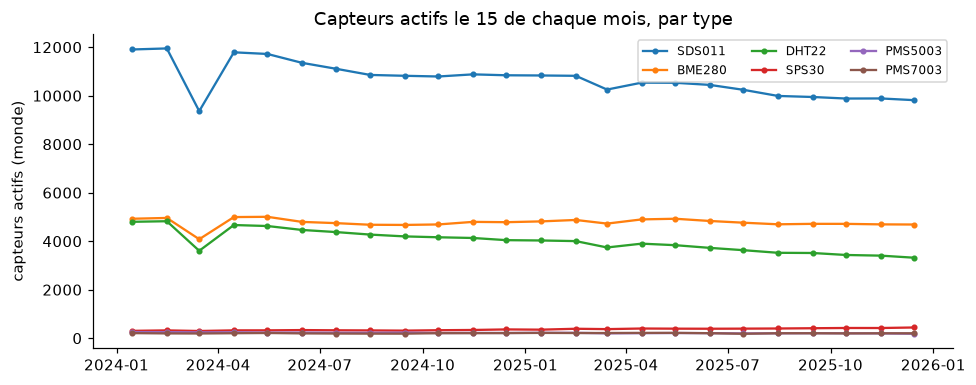

In [5]:
cfg = settings.sensor_community
monthly = (
    listings.filter(pl.col("sensor_type").is_in(cfg.pm_types + cfg.humidity_types))
    .group_by("date", "sensor_type")
    .len()
    .sort("date")
)
fig, ax = plt.subplots(figsize=(9, 3.6))
for sensor_type in ["sds011", "bme280", "dht22", "sps30", "pms5003", "pms7003"]:
    part = monthly.filter(pl.col("sensor_type") == sensor_type)
    ax.plot(part["date"], part["len"], marker="o", ms=3, label=sensor_type.upper())
ax.set_ylabel("capteurs actifs (monde)")
ax.set_title("Capteurs actifs le 15 de chaque mois, par type")
ax.legend(ncols=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_capteurs_actifs_par_mois.png")

**Ce qu'on observe.** 
Le réseau est stable sur la période : entre **9 363 et 11 948 SDS011** actifs le 15 de chaque mois dans le monde,
entre 4 082 et 5 006 BME280, entre 3 319 et 4 824 DHT22. Aucune rupture (panne générale de l'archive, changement de
format) n'apparaît sur 2024–2025 : la période proposée est utilisable telle quelle.

## 3. L'instantané « live » : horloge et précision des positions

**Ce qu'on fait.** On lit l'instantané de l'API live (tous les capteurs ayant émis dans les 5 dernières minutes) et on
compare l'horodatage le plus récent à l'heure UTC à laquelle on a fait la requête.

**Pourquoi.** (1) Il faut connaître le fuseau horaire des capteurs pour les aligner avec les stations.
(2) Le drapeau `exact_location` indique si les coordonnées sont précises ou arrondies.
(3) L'instantané sert aussi à éviter de lire inutilement les capteurs situés aujourd'hui hors d'Allemagne et de France.

In [6]:
live = await discovery.live_snapshot(settings, TODAY)
if "retrieved_at_utc" in live.columns:
    lag = (live["retrieved_at_utc"][0] - live["timestamp"].max()).total_seconds()
    print(f"requête à {live['retrieved_at_utc'][0]} UTC")
    print(f"mesure la plus récente {live['timestamp'].max()} → écart {lag:.0f} s")
print(f"part des capteurs à position exacte : {live['exact_location'].mean():.1%}")
(
    live.filter(
        pl.col("sensor_type").is_in(["sds011", "bme280", "dht22", "sps30"]),
        pl.col("country").is_in(["DE", "FR", "NL", "BE"]),
    )
    .group_by("country", "sensor_type")
    .agg(capteurs=pl.len(), part_indoor=pl.col("indoor").mean().round(3))
    .pivot(on="sensor_type", index="country", values="capteurs")
    .sort("country")
)

requête à 2026-10-13 15:42:20.864558 UTC
mesure la plus récente 2026-10-13 15:41:18 → écart 63 s
part des capteurs à position exacte : 34.4%


country,sds011,sps30,dht22,bme280
str,u32,u32,u32,u32
"""BE""",373,16,260,83
"""DE""",3614,123,1382,1418
"""FR""",250,5,80,125
"""NL""",1203,229,424,571


**Ce qu'on observe.** 
- La mesure la plus récente date de **63 s** avant l'heure UTC de la requête : les horodatages de Sensor.Community sont
  bien en **UTC**.
- Seuls **34 %** des capteurs ont une position exacte ; les autres sont arrondis à 3 décimales (≈ 110 m). C'est sans
  conséquence pour un appariement à 0,5 km ou plus, mais c'est une imprécision à garder en tête pour l'analyse « erreur
  en fonction de la distance ».
- L'Allemagne compte ≈ 3 600 SDS011 actifs aujourd'hui, la France ≈ 250 : d'où le choix de l'Allemagne comme zone
  d'entraînement et de la France comme test de transfert.

## 4. Position de chaque capteur : une requête HTTP *Range* de 2 Ko

**Ce qu'on fait.** Pour chaque capteur de particules ou d'humidité vu dans les listes, on ne télécharge que les
**2 premiers kilo-octets** de son fichier le plus récent (requête HTTP *Range*), on décompresse ce début de fichier
gzip et on lit la première ligne : identifiant de site (`location`), latitude, longitude.

**Pourquoi.** C'est ≈ 3 fois moins de données que de télécharger le fichier entier pour la même information, et
cela ménage les serveurs associatifs. On saute les capteurs que l'instantané live place aujourd'hui hors d'Allemagne
et de France (un capteur aujourd'hui éteint est, lui, toujours lu).

In [7]:
candidates = discovery.head_candidates(
    listings, live, cfg.pm_types + cfg.humidity_types, settings.discovery.countries
)
positions = await discovery.resolve_positions(settings, candidates, TODAY)
inventory = discovery.sensor_inventory(listings, positions, settings)
seen = listings.filter(pl.col("sensor_type").is_in(cfg.pm_types + cfg.humidity_types))["sensor_id"].n_unique()
print(f"capteurs PM/humidité vus dans l'archive : {seen:,}")
print(f"  sautés (à l'étranger aujourd'hui) : {seen - candidates.height:,}")
print(f"  lus par requête Range : {candidates.height:,}")
n_ok, n_fail = positions["lat"].is_not_null().sum(), positions["lat"].is_null().sum()
print(f"  positions obtenues : {n_ok:,} ; échecs : {n_fail:,}")
inventory.group_by("kind").agg(
    capteurs=pl.len(),
    part_indoor=pl.col("indoor").mean().round(3),
    mois_actifs_médian=pl.col("n_months").median(),
)

capteurs PM/humidité vus dans l'archive : 32,285
  sautés (à l'étranger aujourd'hui) : 8,909
  lus par requête Range : 23,376
  positions obtenues : 23,477 ; échecs : 0


kind,capteurs,part_indoor,mois_actifs_médian
str,u32,f64,f64
"""humidity""",10571,0.049,15.0
"""pm""",12906,0.045,15.0


**Ce qu'on observe.** 
Sur 32 285 capteurs de particules ou d'humidité vus dans l'archive, **8 909 ont été sautés** (l'instantané live les
situe aujourd'hui hors d'Allemagne et de France) et ≈ 23 400 ont été lus en **≈ 6 minutes, sans aucun échec**
(≈ 65 requêtes par seconde). L'inventaire compte 12 906 capteurs de particules et 10 571 sondes d'humidité, actifs en
médiane 15 mois sur 24. Anomalie relevée : **54 capteurs déclarent la position (0 ; 0)** (« Null Island », dans le golfe
de Guinée), un défaut de configuration ; ils ne peuvent être appariés à aucune station, ce qui est le comportement voulu.

## 5. Les stations officielles (EEA)

**Ce qu'on fait.** On télécharge les métadonnées de toutes les stations européennes, on ne garde que les points de
mesure PM2.5 **automatiques** (qui donnent une valeur par heure) disposant d'un fichier horaire **E1a**, en Allemagne et en France.

**Pourquoi.** *E1a* = données **vérifiées** par les pays (contrairement à *E2a*, le flux temps réel non vérifié).
Une station peut abriter plusieurs instruments : on parle de *points de prélèvement* (sampling points).

In [8]:
stations = await discovery.eea_stations(settings, "pm25")
print(f"{stations.height} points PM2.5 horaires E1a, {stations['station_code'].n_unique()} stations")
stations.group_by("country", "station_type").agg(
    points=pl.len(), stations=pl.col("station_code").n_unique()
).sort("country", "station_type")

682 points PM2.5 horaires E1a, 682 stations


country,station_type,points,stations
str,str,u32,u32
"""DE""","""background""",240,240
"""DE""","""industrial""",21,21
"""DE""","""traffic""",121,121
"""FR""","""background""",214,214
"""FR""","""industrial""",13,13
"""FR""","""traffic""",73,73


In [9]:
stations.group_by("country", "measurement_method").len().sort("country", "len", descending=[False, True])

country,measurement_method,len
str,str,u32
"""DE""","""light-scat""",283
"""DE""","""nephelometry+beta""",62
"""DE""","""TEOM""",21
"""DE""","""BETA""",16
"""FR""","""OPC-CMC""",145
"""FR""","""TEOM-FDMS""",81
"""FR""","""BETA""",61
"""FR""","""""",13


**Ce qu'on observe.** 
On obtient **682 points de prélèvement PM2.5 horaires vérifiés** (382 en Allemagne, 300 en France métropolitaine),
un seul par station. Les 25 stations françaises d'outre-mer sont écartées : leurs métadonnées déclarent une autre
horloge (UTC−4, UTC−3, UTC+3, UTC+4) et aucun capteur citoyen n'en est proche. Les stations de **fond** (*background* : éloignées des sources directes de pollution) sont majoritaires, mais un
tiers des stations allemandes sont des stations **trafic** (en bord de route). Les instruments diffèrent selon le pays :
diffusion de lumière (`light-scat`, type Fidas) en Allemagne, compteur optique (`OPC-CMC`) et microbalance
(`TEOM-FDMS`) en France. La vérité terrain n'est donc pas parfaitement homogène entre les deux pays : c'est une limite
à garder en tête pour le test de transfert. Par ailleurs, 19 points PM2.5 automatiques européens (dont 1 en France)
n'ont pas de coordonnées dans les métadonnées et sont écartés.

**Ce qu'on fait.** On ouvre un fichier E1a réel (la première station allemande téléchargée) pour en lire la structure : colonnes,
types, drapeaux de validité et de vérification.

**Pourquoi.** Il faut savoir quelles heures garder. Le vocabulaire officiel de l'EEA définit :
`Validity` −1 = non valide, −99 = maintenance, 1 = valide, 2 = valide mais sous la limite de détection,
3 = idem remplacé par la moitié de la limite ; `Verification` 1 = vérifié, 2 = préliminaire, 3 = non vérifié.

In [10]:
from aircalib.ingest.http import polite_client

downloaded = pl.read_parquet(settings.paths.meta / "eea_pm25_monthly_valid_hours.parquet")[
    "sampling_point"
].unique()
example = (
    stations.filter(pl.col("country") == "DE", pl.col("sampling_point").is_in(downloaded.implode()))
    .sort("sampling_point")
    .row(0, named=True)
)
one_path = discovery.eea_raw_path(settings, "pm25", "DE", example["sampling_point"])
if not one_path.exists():  # raw files are deleted once bronze holds them (eea.keep_raw): fetch this one again
    async with polite_client(settings.http) as client:
        await eea.download_parquet(client, example["url"], one_path)
one = pl.read_parquet(one_path)
print(
    example["station_name"],
    "·",
    example["station_type"],
    example["station_area"],
    "·",
    one_path.name,
    one.shape,
)
print(one.schema)
obs_one = eea.scan_observations(one_path).collect()
(
    obs_one.group_by(year=pl.col("start").dt.year())
    .agg(
        heures=pl.len(),
        valides=pl.col("validity").is_in(settings.eea.valid_codes).sum(),
        sentinelle_m999=(pl.col("value") == settings.eea.missing_sentinel).sum(),
        vérifiées=(pl.col("verification") == 1).sum(),
        min=pl.col("value").filter(pl.col("validity") > 0).min(),
        max=pl.col("value").max(),
    )
    .sort("year")
    .tail(4)
)

Potsdam-Zentrum · background urban · SPO.DE_DEBB021_PM2_dataGroup1.parquet (113952, 12)
Schema({'Samplingpoint': String, 'Pollutant': Int32, 'Start': Datetime(time_unit='ns', time_zone=None), 'End': Datetime(time_unit='ns', time_zone=None), 'Value': Decimal(precision=38, scale=18), 'Unit': String, 'AggType': String, 'Validity': Int32, 'Verification': Int32, 'ResultTime': Datetime(time_unit='ns', time_zone=None), 'DataCapture': Decimal(precision=38, scale=18), 'FkObservationLog': String})


year,heures,valides,sentinelle_m999,vérifiées,min,max
i32,u32,u32,u32,u32,f64,f64
2022,8760,8737,23,8760,0.789999,87.191368
2023,8760,8228,532,8760,0.916219,42.245056
2024,8784,8761,23,8784,1.34956,164.329467
2025,8760,8738,22,8760,1.047199,66.887176


**Ce qu'on observe.** 
Le fichier contient **tout l'historique** de la station depuis 2013 (113 952 heures) : une ligne par heure, sans doublon
et sans trou, y compris aux changements d'heure (l'horloge ne suit donc pas l'heure d'été). `Value` est un décimal
haute précision, converti en nombre flottant. Les heures manquantes ne sont pas absentes : elles sont codées **−999**
avec `Validity = −1` (23 heures en 2024). Point clé : 2024 et 2025 sont **entièrement vérifiés** (`Verification = 1`),
la vérité terrain E1a couvre donc toute la période d'étude.

340 points ; médiane = 99.1% des heures


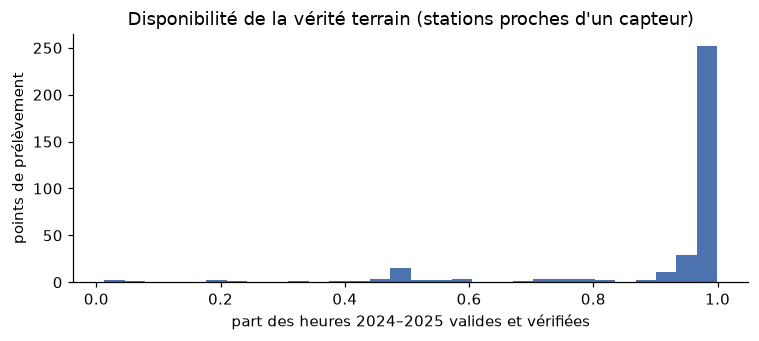

In [11]:
availability = pl.read_parquet(settings.paths.meta / "eea_pm25_monthly_valid_hours.parquet")
per_point = availability.group_by("sampling_point").agg(heures_valides=pl.col("valid_hours").sum())
hours_in_period = (settings.period.end - settings.period.start).days * 24 + 24
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_point["heures_valides"] / hours_in_period, bins=30, color="#4C72B0")
ax.set_xlabel("part des heures 2024–2025 valides et vérifiées")
ax.set_ylabel("points de prélèvement")
ax.set_title("Disponibilité de la vérité terrain (stations proches d'un capteur)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_disponibilite_eea.png")
median_share = (per_point["heures_valides"] / hours_in_period).median()
print(f"{per_point.height} points ; médiane = {median_share:.1%} des heures")

**Ce qu'on observe.** 
On a téléchargé les 381 stations PM2.5 situées à moins de 3 km d'un capteur ; 340 ont des données valides et vérifiées
en 2024–2025 (les 41 autres ont fermé ou changé d'instrument avant 2024). Pour ces 340 points, la médiane est de
**99 % d'heures utilisables**. La référence n'est pas le facteur limitant : ce sont les capteurs citoyens.

## 6. Sur quelle horloge sont les stations ? (contrôle par corrélation décalée)

**Ce qu'on fait.** Les horodatages EEA n'ont pas de fuseau explicite. Les métadonnées annoncent `UTC+01` pour l'Allemagne
et `UTC` pour la France, et la série ne présente aucun trou au changement d'heure (donc pas d'heure d'été). On le vérifie
empiriquement : pour quelques capteurs SDS011 à moins de 500 m d'une station, on calcule la moyenne horaire du capteur
(en UTC, heure étiquetée par son début) puis la **corrélation de Pearson** avec la station en décalant la station de
$k$ heures :

$$
r(k) = \operatorname{corr}\big(\,x_{\text{capteur}}(h),\; y_{\text{station}}(h + k)\,\big), \qquad k \in \{-3, \dots, +3\}
$$

**Pourquoi.** Si la station est en UTC+1 et étiquette l'heure par son début, le meilleur alignement est $k = +1$.
Une erreur d'une heure dans l'alignement suffirait à dégrader artificiellement tous les modèles.

shape: (7, 7)
┌─────────┬───────────┬───────────────────────────────┬─────────────┬───────┬───────────┬─────────┐
│ country ┆ sensor_id ┆ sampling_point                ┆ distance_km ┆ lag_h ┆ pearson_r ┆ n_hours │
│ ---     ┆ ---       ┆ ---                           ┆ ---         ┆ ---   ┆ ---       ┆ ---     │
│ str     ┆ i32       ┆ str                           ┆ f64         ┆ i64   ┆ f64       ┆ i64     │
╞═════════╪═══════════╪═══════════════════════════════╪═════════════╪═══════╪═══════════╪═════════╡
│ FR      ┆ 65706     ┆ SPO-FR02020_6001              ┆ 0.133495    ┆ 1     ┆ 0.975464  ┆ 331     │
│ FR      ┆ 90258     ┆ SPO-FR12042_6001              ┆ 0.253462    ┆ 1     ┆ 0.954563  ┆ 335     │
│ DE      ┆ 515       ┆ SPO.DE_DEBW107_PM2_dataGroup1 ┆ 0.069007    ┆ 1     ┆ 0.937027  ┆ 324     │
│ DE      ┆ 81044     ┆ SPO.DE_DEBB044_PM2_dataGroup1 ┆ 0.0333      ┆ 1     ┆ 0.935762  ┆ 334     │
│ FR      ┆ 82196     ┆ SPO-FR12021_6001              ┆ 0.054572    ┆ 1     ┆ 0.909766

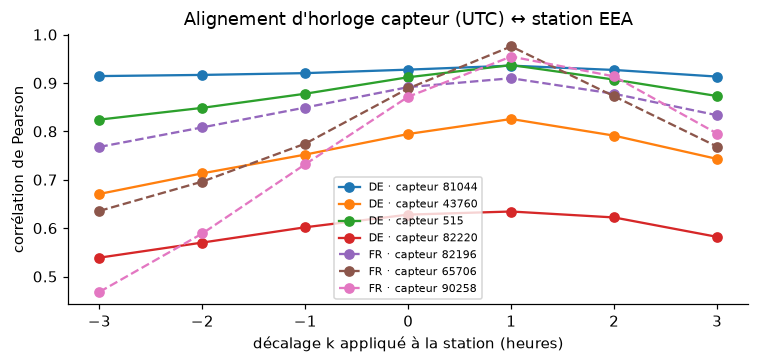

In [12]:
lags = pl.read_parquet(settings.paths.meta / "eea_clock_lag_check.parquet")
best = (
    lags.sort("pearson_r", descending=True)
    .group_by("country", "sensor_id", "sampling_point", maintain_order=True)
    .first()
)
print(best.select("country", "sensor_id", "sampling_point", "distance_km", "lag_h", "pearson_r", "n_hours"))
fig, ax = plt.subplots(figsize=(7, 3.4))
for (country, sensor_id), part in lags.group_by("country", "sensor_id", maintain_order=True):
    ax.plot(
        part["lag_h"],
        part["pearson_r"],
        marker="o",
        ls="-" if country == "DE" else "--",
        label=f"{country} · capteur {sensor_id}",
    )
ax.set_xlabel("décalage k appliqué à la station (heures)")
ax.set_ylabel("corrélation de Pearson")
ax.set_title("Alignement d'horloge capteur (UTC) ↔ station EEA")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_controle_horloge.png")

**Ce qu'on observe.** 
Pour les **7 paires testées** (4 en Allemagne, 3 en France), la corrélation est maximale pour **k = +1 h, sans
exception** (r jusqu'à 0,98 ; la courbe est nettement en pointe). Autrement dit, la valeur que l'EEA étiquette
`Start = 14:00` correspond à l'heure 13:00–14:00 UTC.

- Allemagne : cohérent avec les métadonnées (`UTC+01`, heure étiquetée par son début).
- France : les métadonnées annoncent `UTC`, mais les données se comportent de la même façon. Indice concordant : la
  série française de 2013 commence à `01:00` et chaque fichier contient une seule ligne datée du 1ᵉʳ janvier de
  l'année suivante à `00:00`. Soit l'heure française est étiquetée par sa **fin**, soit l'horloge est UTC+1 : les deux
  hypothèses donnent la même règle.

**Règle retenue pour tout le projet :**

$$
\text{heure}_{\text{UTC}} = \texttt{Start} - 1\ \text{h}
$$

pour les deux pays (heure étiquetée par son **début**, en UTC). Elle sera re-vérifiée automatiquement sur chaque paire
à l'étape 3. Sans ce contrôle, la France aurait été décalée d'une heure.

## 7. Combien de paires capteur ↔ station ?

**Ce qu'on fait.** Pour chaque capteur de particules **extérieur**, on calcule la distance à chaque station
(formule de haversine, distance sur la sphère terrestre) :

$$
d = 2R \arcsin\!\sqrt{\sin^2\!\frac{\varphi_2-\varphi_1}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\!\frac{\lambda_2-\lambda_1}{2}}, \qquad R = 6371\ \text{km}
$$

où $\varphi$ est la latitude et $\lambda$ la longitude en radians.

**Règle d'appariement : 1 capteur = 1 station.** Un capteur peut avoir plusieurs stations à moins de 3 km (jusqu'à 6) ;
on garde **la plus proche ayant des heures vérifiées pendant que le capteur est actif**, et on conserve sa distance.
Plusieurs capteurs peuvent en revanche partager la même station. Pour chaque rayon, on compte :

- `n_pairs` = `n_sensors` : paires capteur ↔ station (une par capteur) ;
- `n_stations` : stations distinctes utilisées ;
- `median_overlap_h` : recouvrement temporel estimé, en heures, d'un capteur avec sa station la plus proche =
  somme, sur les mois où le capteur est actif, des heures valides et vérifiées de la station ;
- `humidity_share` : part des capteurs qui ont une sonde d'humidité active **sur le même site** ;
- `traffic_share` : part des paires dont la station est une station **trafic** (en bord de route).

> **Correction du 14/10/2026.** La première version de ce tableau comptait tous les *couples* capteur ↔ station à
> moins du rayon (en Allemagne à 3 km : 1 876 couples pour 1 269 capteurs). Le nombre de capteurs était juste, mais
> le nombre de paires et de stations était gonflé. Le code applique désormais la règle ci-dessus (voir le journal).

**Pourquoi.** C'est le cœur du GO / NO-GO : il faut assez de paires, sur assez de stations différentes
(la validation croisée se fera *par station*), avec assez d'heures communes et une sonde d'humidité.

In [13]:
pairs = pl.read_parquet(settings.paths.meta / "candidate_pairs.parquet")
assert pairs["sensor_id"].is_unique().all(), "one station per sensor"
print(
    "stations à portée par capteur (≤ 3 km) :",
    dict(pairs["n_stations_within"].value_counts().sort("n_stations_within").iter_rows()),
)
summary = discovery.feasibility_summary(pairs, settings.discovery.radii_km)
summary.with_columns(
    pl.col("humidity_share", "traffic_share").round(2), pl.col("total_overlap_h") / 1000
).rename({"total_overlap_h": "total_overlap_kh"})

stations à portée par capteur (≤ 3 km) : {1: 932, 2: 392, 3: 92, 4: 26, 5: 3, 6: 4}


country,radius_km,n_pairs,n_sensors,n_stations,median_overlap_h,total_overlap_kh,humidity_share,traffic_share
str,f64,u32,u32,u32,f64,f64,f64,f64
"""DE""",0.5,127,127,74,13055.0,1418.901,0.85,0.64
"""DE""",1.0,337,337,147,12287.0,3683.914,0.84,0.61
"""DE""",1.5,568,568,179,12473.5,6224.304,0.84,0.57
"""DE""",2.0,808,808,199,13008.5,9002.469,0.81,0.57
"""DE""",3.0,1268,1268,241,13094.5,14287.052,0.81,0.54
"""FR""",0.5,11,11,11,13719.0,125.171,0.73,0.18
"""FR""",1.0,30,30,26,12156.5,345.555,0.77,0.3
"""FR""",1.5,62,62,43,11010.5,647.884,0.76,0.34
"""FR""",2.0,97,97,53,10164.0,945.978,0.75,0.31


**Ce qu'on observe.** 
- **Une station par capteur** : 932 capteurs n'ont qu'une station utilisable à moins de 3 km, 392 en ont deux et 125
  en ont trois ou plus ; la règle garde la plus proche.
- **Allemagne** : le nombre de capteurs appariables croît vite avec le rayon : 127 à 0,5 km, 337 à 1 km, **568 à
  1,5 km (179 stations)**, 808 à 2 km et 1 268 à 3 km (241 stations). Un capteur frontalier, compté autrefois dans les
  deux pays, est désormais rattaché au seul pays de sa station la plus proche.
- Le **recouvrement temporel** médian reste ≈ 12 500 heures (≈ 70 % des 17 544 heures de la période) quel que soit le
  rayon.
- **Humidité** : ≈ 84 % des capteurs allemands ont une sonde d'humidité active sur le même site, la condition pour la
  correction physique et les features météo est donc remplie.
- **France** : neuf fois moins dense, 62 capteurs à 1,5 km (43 stations), 181 à 3 km (67 stations). Suffisant pour un
  **test de transfert**, pas pour entraîner.
- Le type de capteur est quasi uniforme : à 1,5 km, **559 des 568** capteurs allemands sont des SDS011 (en France :
  48 sur 62, plus 11 PMS7003).

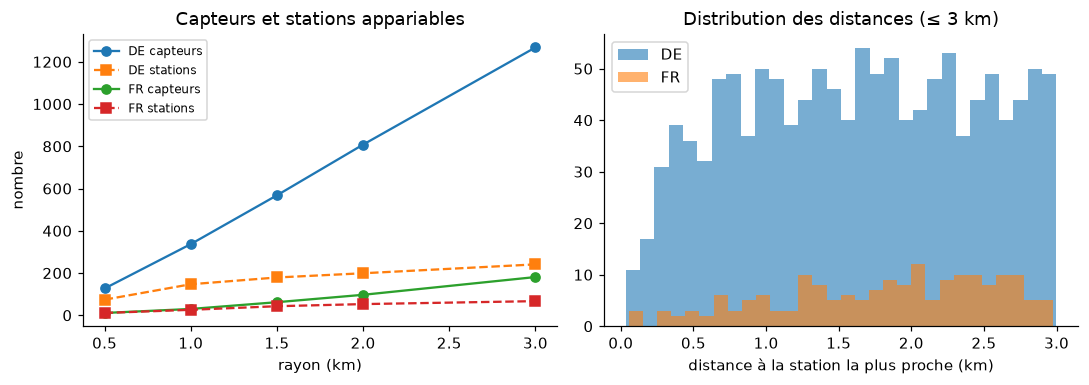

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for country, part in summary.group_by("country", maintain_order=True):
    axes[0].plot(part["radius_km"], part["n_sensors"], marker="o", label=f"{country[0]} capteurs")
    axes[0].plot(part["radius_km"], part["n_stations"], marker="s", ls="--", label=f"{country[0]} stations")
axes[0].set_xlabel("rayon (km)")
axes[0].set_ylabel("nombre")
axes[0].set_title("Capteurs et stations appariables")
axes[0].legend(fontsize=8)
nearest = pairs.sort("distance_km").unique("sensor_id", keep="first")
for country, part in nearest.group_by("country", maintain_order=True):
    axes[1].hist(part["distance_km"], bins=30, alpha=0.6, label=country[0])
axes[1].set_xlabel("distance à la station la plus proche (km)")
axes[1].set_title("Distribution des distances (≤ 3 km)")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_paires_par_rayon.png")

In [15]:
radius = 1.5
chosen = (
    pairs.filter(pl.col("distance_km") <= radius, pl.col("overlap_hours") > 0)
    .sort("distance_km")
    .unique("sensor_id", keep="first")
)
chosen.group_by("country", "station_type").agg(
    capteurs=pl.len(),
    stations=pl.col("station_code").n_unique(),
    heures_kh=(pl.col("overlap_hours").sum() / 1000).round(1),
).sort("country", "station_type")

country,station_type,capteurs,stations,heures_kh
str,str,u32,u32,f64
"""DE""","""background""",231,88,2556.0
"""DE""","""industrial""",12,7,107.1
"""DE""","""traffic""",325,84,3561.2
"""FR""","""background""",39,27,399.9
"""FR""","""industrial""",2,2,28.0
"""FR""","""traffic""",21,14,219.9


**Ce qu'on observe.** 
À 1,5 km en Allemagne, **325 capteurs sur 568** ont pour station la plus proche une station **trafic**. La référence
y est mesurée en bord de route, alors que le capteur citoyen est souvent sur un balcon d'une rue voisine : une partie
de l'écart capteur ↔ station ne vient pas du capteur mais de la différence de lieu (*erreur de représentativité*).
La correction ne peut pas la supprimer. Le type de station sera une variable du modèle et un axe d'analyse des
résultats.

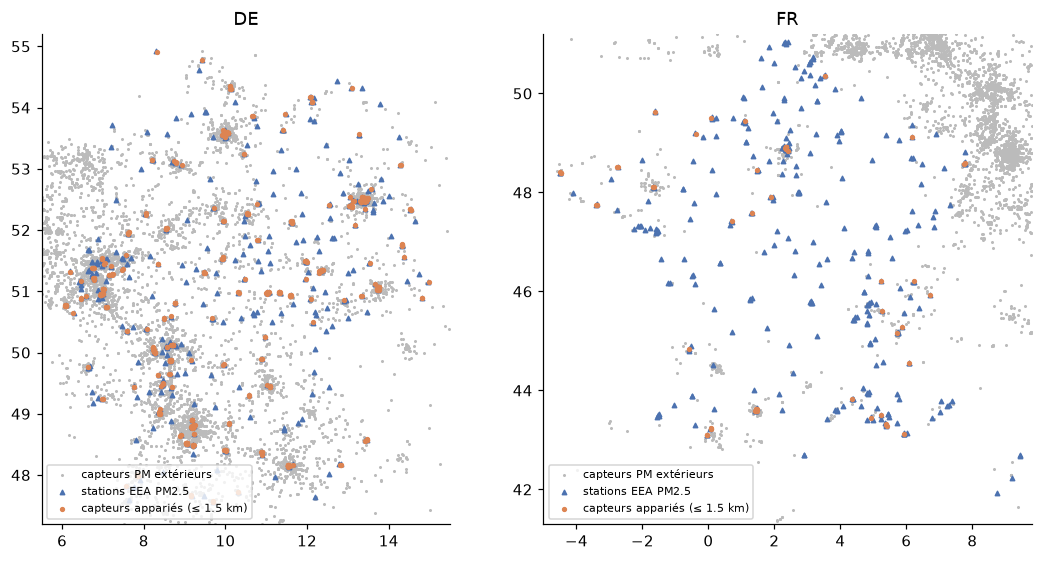

In [16]:
inv = pl.read_parquet(settings.paths.meta / "sc_inventory.parquet")
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
boxes = {"DE": (5.5, 15.5, 47.2, 55.2), "FR": (-5.0, 9.8, 41.3, 51.2)}
for ax, (country, (x0, x1, y0, y1)) in zip(axes, boxes.items(), strict=True):
    pm = inv.filter(
        pl.col("kind") == "pm",
        ~pl.col("indoor"),
        pl.col("lon").is_between(x0, x1),
        pl.col("lat").is_between(y0, y1),
    )
    st = stations.filter(
        pl.col("country") == country, pl.col("lon").is_between(x0, x1), pl.col("lat").is_between(y0, y1)
    )
    pr = chosen.filter(pl.col("country") == country)
    ax.scatter(pm["lon"], pm["lat"], s=1, c="#BBBBBB", label="capteurs PM extérieurs")
    ax.scatter(st["lon"], st["lat"], s=8, c="#4C72B0", marker="^", label="stations EEA PM2.5")
    ax.scatter(
        pr["sensor_lon"], pr["sensor_lat"], s=6, c="#DD8452", label=f"capteurs appariés (≤ {radius} km)"
    )
    ax.set_title(country)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect(1.5)
    ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_carte_paires.png")

## 8. Volume disque attendu

**Ce qu'on fait.** On télécharge une semaine réelle pour quelques capteurs appariés de chaque type, on mesure la taille
du fichier gzip et celle du même contenu converti en Parquet compressé (zstd), puis on extrapole aux capteurs
retenus sur 731 jours.

**Pourquoi.** Le budget est de 5–10 Go au final et 20 Go en pic. On veut un ordre de grandeur mesuré, pas supposé.

In [17]:
humidity_sites = inv.filter(pl.col("kind") == "humidity", ~pl.col("indoor")).select(
    "sensor_id", "sensor_type", "location_id"
)
chosen_humidity = humidity_sites.join(chosen.select("location_id").unique(), on="location_id")
probe_set = pl.concat(
    [
        chosen.filter(pl.col("sensor_type") == "sds011").head(4).select("sensor_type", "sensor_id"),
        chosen_humidity.filter(pl.col("sensor_type") == "bme280").head(3).select("sensor_type", "sensor_id"),
        chosen_humidity.filter(pl.col("sensor_type") == "dht22").head(3).select("sensor_type", "sensor_id"),
    ]
)
probe = await discovery.size_probe(settings, probe_set, date(2025, 3, 3), 7, TODAY)
probe.group_by("sensor_type").agg(
    capteurs=pl.len(),
    lignes_par_jour=(pl.col("rows").sum() / pl.col("days").sum()).round(0),
    ko_gz_par_jour=(pl.col("gz_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
    ko_parquet_1_fichier_par_jour=(pl.col("parquet_daily_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
    ko_parquet_regroupé=(pl.col("parquet_batched_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
).sort("sensor_type")

sensor_type,capteurs,lignes_par_jour,ko_gz_par_jour,ko_parquet_1_fichier_par_jour,ko_parquet_regroupé
str,u32,f64,f64,f64,f64
"""bme280""",3,456.0,5.6,8.5,5.0
"""dht22""",1,553.0,3.4,6.0,3.0
"""sds011""",3,540.0,5.3,8.6,4.5


In [18]:
per_day = probe.select(
    gz=pl.col("gz_bytes").sum() / pl.col("days").sum(),
    bronze=pl.col("parquet_batched_bytes").sum() / pl.col("days").sum(),
).row(0, named=True)
# Measured at step 1 on the raw files (since deleted once in bronze, see the journal); 0 if absent.
eea_pm25 = sum(p.stat().st_size for p in (settings.paths.raw / "eea" / "pm25").rglob("*.parquet"))
rows = []
for r in (1.0, 1.5, 3.0):
    sel = (
        pairs.filter(pl.col("distance_km") <= r, pl.col("overlap_hours") > 0)
        .sort("distance_km")
        .unique("sensor_id", keep="first")
    )
    hum = humidity_sites.join(sel.select("location_id").unique(), on="location_id")
    active = sel["overlap_hours"].sum() / (sel.height * hours_in_period)
    days = (sel.height + hum.height) * 731 * active
    rows.append(
        {
            "rayon_km": r,
            "capteurs_PM": sel.height,
            "sondes_humidité": hum.height,
            "part_jours_actifs": round(active, 2),
            "fichiers_capteur_jour": int(days),
            "téléchargement_gz_Go": round(days * per_day["gz"] / 1e9, 2),
            "bronze_parquet_Go": round(days * per_day["bronze"] / 1e9, 2),
        }
    )
print(f"EEA PM2.5 (stations à ≤ 3 km, historique complet 2013–2025) : {eea_pm25 / 1e9:.2f} Go")
pl.DataFrame(rows)

EEA PM2.5 (stations à ≤ 3 km, historique complet 2013–2025) : 0.40 Go


rayon_km,capteurs_PM,sondes_humidité,part_jours_actifs,fichiers_capteur_jour,téléchargement_gz_Go,bronze_parquet_Go
f64,i64,i64,f64,i64,f64,f64
1.0,367,314,0.63,311542,1.61,1.4
1.5,630,532,0.62,528140,2.72,2.37
3.0,1449,1170,0.63,1202454,6.2,5.4


**Ce qu'on observe.** 
- Mesuré sur une semaine réelle (6 capteurs actifs × 7 jours) : ≈ 4–6 Ko par jour en gzip, ≈ 3–6 Ko en Parquet si les
  jours sont **regroupés** dans un même fichier. Écrit « un fichier par jour », le Parquet est *plus gros* que le gzip
  (en-tête de chaque fichier) : la couche bronze regroupera donc les jours par capteur et par mois.
- **À 1,5 km** : ≈ 0,53 million de fichiers capteur-jour (630 capteurs PM + 532 sondes d'humidité), ≈ 2,8 Go
  transférés puis supprimés, ≈ **2,5 Go en bronze**. À 3 km : ≈ 5,6 Go. À ajouter : ≈ 0,8 Go pour l'EEA (PM2.5 + PM10).
- Le facteur limitant est le **temps** plus que la place : au débit mesuré (≈ 65 requêtes/s), 1,5 km représente
  ≈ 3 h de téléchargement, 3 km ≈ 6 h (une seule fois, reprenable).

## 9. Conclusion : GO / NO-GO

**Recommandation : GO.**

| Critère | Valeur mesurée | Verdict |
|---|---|---|
| Rayon d'appariement retenu | **1,5 km** (station la plus proche) | compromis taille / représentativité |
| Période | 2024-01-01 → 2025-12-31, vérité terrain E1a 100 % vérifiée | ✅ |
| Paires Allemagne (entraînement) | **568 capteurs**, 179 stations, ≈ 6,2 millions d'heures communes estimées | ✅ largement suffisant pour une validation croisée par station |
| Paires France (transfert) | 62 capteurs, 43 stations, ≈ 0,65 million d'heures | ✅ suffisant pour un test |
| Sonde d'humidité sur le même site | 84 % (DE), 76 % (FR) | ✅ |
| Alignement horaire | vérifié : `heure_UTC = Start − 1 h` (DE et FR) | ✅ |
| Disque estimé | ≈ 2,5 Go bronze capteurs + ≈ 0,8 Go EEA (+ silver/gold < 1 Go) | ✅ (budget 5–10 Go) |
| Temps de téléchargement | ≈ 3 h, une fois, reprenable | acceptable |

Pourquoi 1,5 km plutôt que 0,5 km ou 3 km : à 0,5 km il ne reste que 127 capteurs (75 stations), trop peu pour une
validation croisée par station robuste ; à 3 km le volume double (1 268 capteurs) mais l'écart de représentativité
capteur ↔ station grandit et brouille la cible. À 1,5 km on garde 568 capteurs, et la distance (0 → 1,5 km) varie assez
pour étudier l'erreur en fonction de la distance — la seconde moitié de la question business.

**Périmètre proposé** : modèle centré sur le **SDS011** (98 % des paires allemandes) ; les autres types sont exclus
de l'entraînement et le choix est documenté.

**Risques identifiés, et leur parade** :

1. humidité saturée ou figée chez ≈ la moitié des mesures d'un échantillon de mars → règle de qualité dédiée (étape 3) ;
2. 57 % des capteurs allemands appariés sont près d'une station trafic → type de station en variable et en axe d'analyse ;
3. activité connue au mois près → recalculée exactement à l'étape 2 ;
4. instruments de référence différents entre pays → limite explicite du test de transfert.

**Décision prise le 14/10/2026 (feu vert pour l'étape 2).** On **télécharge toutes les paires jusqu'à 3 km** mais on
**n'entraîne que sur les paires ≤ 1,5 km** ; les paires entre 1,5 et 3 km forment un jeu de test « distance » qui
répond directement à la seconde moitié de la question business (erreur en fonction de la distance). Le découpage
de validation croisée par station s'applique à toutes les distances : une station n'est jamais à la fois en
entraînement et en test. Seul le **SDS011** est conservé (`configs/default.yaml`, section `pairing`).